# Ćwiczenie 12: Analiza radiomiczna RTG miednicy — wczesne wykrywanie jałowej martwicy głowy kości udowej (*AVN*)

## Opis przypadku klinicznego
Analizowany obraz to przeglądowy rentgenogram (RTG) miednicy i obu stawów biodrowych w projekcji przednio-tylnej u pacjenta z wczesnym stadium **jałowej martwicy prawej głowy kości udowej** (*Aseptic / Avascular Necrosis of Femoral Head — AVN*, stadium II wg klasyfikacji Ficata–Arleta).

* **Prawa głowa kości udowej (widoczna po lewej stronie zdjęcia RTG):** Zarys sferyczny stawu nie uległ jeszcze zapadnięciu, jednak w górno-bocznej strefie obciążanej (*superolateral weight-bearing dome*) zachodzi **przebudowa sklerotyczno-osteopeniczna** — ogniska reaktywnej osteosklerozy (zagęszczenia kości) sąsiadują ze strefami resorpcji i zatarciem prawidłowego rysunku beleczkowego.
* **Lewa głowa kości udowej (widoczna po prawej stronie zdjęcia, przy znaczniku „L”):** Prawidłowa, jednorodna architektura beleczkowa kości gąbczastej — stanowi naturalny **obszar referencyjny (kontrolny)**.

## Cel zadania
Wczesne stadium AVN bywa trudne do jednoznacznej oceny wizualnej na klasycznym zdjęciu RTG. Twoim zadaniem jest uzupełnienie funkcji ekstrakcji **cech radiomicznych 1. rzędu (statystyk histogramu)** oraz **cech tekstury 2. rzędu (macierzy GLCM)**, porównanie wektora biomarkerów obu głów kości udowych oraz zinterpretowanie uzyskanych różnic.

Uzupełnij brakujące fragmenty kodu oznaczone komentarzem `# TODO`.

In [4]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK scikit-image pandas

import os
import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from skimage.feature import graycomatrix, graycoprops

print(f"Środowisko gotowe (SimpleITK {sitk.__version__})")

Środowisko gotowe (SimpleITK 2.5.7)


---
## Krok 1: Wczytanie obrazu RTG i zdefiniowanie masek ROI obu głów kości udowych

Upewnij się, że plik ze zdjęciem RTG miednicy znajduje się w tym samym folderze co notatnik pod nazwą **`rtg_miednica.jpg`**.

Poniższa komórka wczytuje obraz w skali szarości do obiektu `SimpleITK`, wyznacza dwie symetryczne maski eliptyczne w górno-bocznej strefie obciążanej:
* **`mask_right_sitk`** — prawa głowa kości udowej (zmieniona chorobowo — AVN),
* **`mask_left_sitk`** — lewa głowa kości udowej (zdrowa tkanka referencyjna),

a następnie wyświetla oba obszary ROI oraz ich znormalizowane histogramy intensywności.

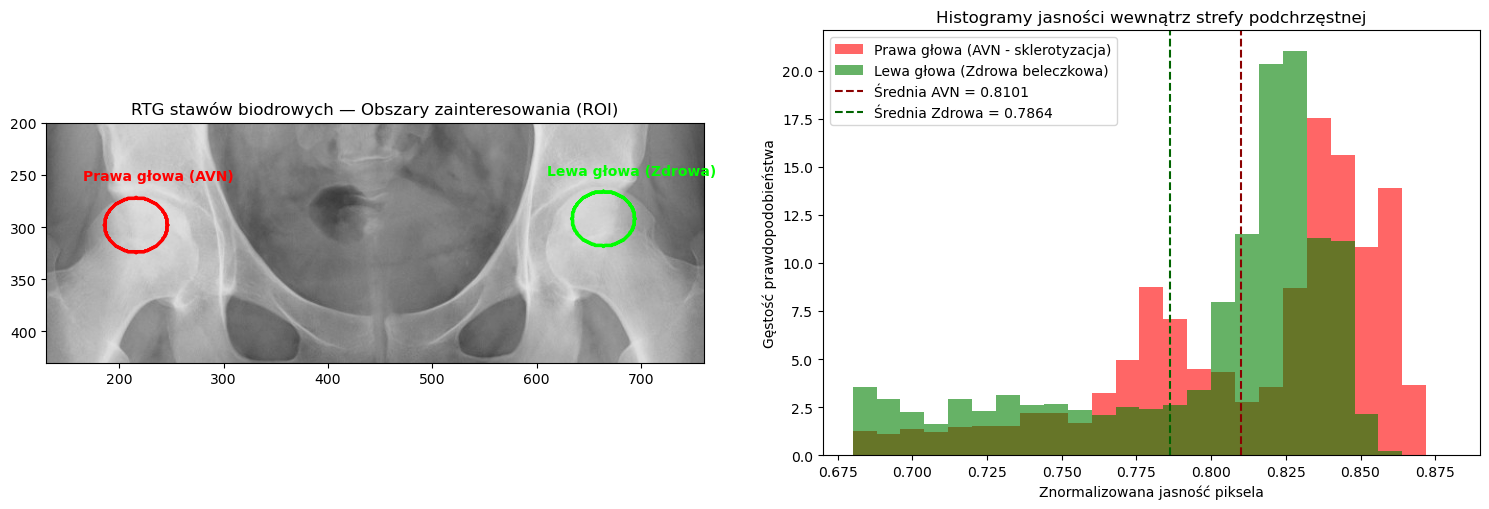

In [7]:
# 1. Wczytanie obrazu RTG (automatyczne wyszukiwanie rozszerzenia .png / .jpg / .jpeg)
IMAGE_PATH = "sample photos/jpeg/rtg_miednica.jpg"

gray_arr = np.array(Image.open(IMAGE_PATH).convert("L"), dtype=np.float32) / 255.0
rtg_img = sitk.GetImageFromArray(gray_arr)
rtg_img.SetSpacing((1.0, 1.0))
rtg_img.SetOrigin((0.0, 0.0))

rtg_np = sitk.GetArrayFromImage(rtg_img)
H, W = rtg_np.shape
y, x = np.mgrid[0:H, 0:W].astype(np.float32)

# 2. Definicja masek ROI w strefie obciążanej (superolateral weight-bearing dome)
# Prawa głowa kości udowej (AVN - po lewej stronie zdjęcia RTG)
mask_right_np = (((x - 216.0) / 30.0)**2 + ((y - 298.0) / 26.0)**2 <= 1.0).astype(np.uint8)
# Lewa głowa kości udowej (Zdrowa - po prawej stronie zdjęcia RTG)
mask_left_np = (((x - 664.0) / 30.0)**2 + ((y - 292.0) / 26.0)**2 <= 1.0).astype(np.uint8)

mask_right_sitk = sitk.GetImageFromArray(mask_right_np)
mask_right_sitk.CopyInformation(rtg_img)

mask_left_sitk = sitk.GetImageFromArray(mask_left_np)
mask_left_sitk.CopyInformation(rtg_img)

# 3. Wizualizacja ROI oraz rozkładów intensywności 1. rzędu
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))

ax[0].imshow(rtg_np, cmap='gray', vmin=0, vmax=1)
ax[0].contour(mask_right_np, colors='red', linewidths=1.8)
ax[0].contour(mask_left_np, colors='lime', linewidths=1.8)
ax[0].set_xlim(130, 760)
ax[0].set_ylim(430, 200)
ax[0].text(165, 255, "Prawa głowa (AVN)", color='red', fontweight='bold', fontsize=10)
ax[0].text(610, 250, "Lewa głowa (Zdrowa)", color='lime', fontweight='bold', fontsize=10)
ax[0].set_title("RTG stawów biodrowych — Obszary zainteresowania (ROI)")

vals_r = rtg_np[mask_right_np > 0]
vals_l = rtg_np[mask_left_np > 0]
ax[1].hist(vals_r, bins=25, range=(0.68, 0.88), density=True, alpha=0.6, color='red', label='Prawa głowa (AVN - sklerotyzacja)')
ax[1].hist(vals_l, bins=25, range=(0.68, 0.88), density=True, alpha=0.6, color='green', label='Lewa głowa (Zdrowa beleczkowa)')
ax[1].axvline(np.mean(vals_r), color='darkred', linestyle='--', linewidth=1.5, label=f'Średnia AVN = {np.mean(vals_r):.4f}')
ax[1].axvline(np.mean(vals_l), color='darkgreen', linestyle='--', linewidth=1.5, label=f'Średnia Zdrowa = {np.mean(vals_l):.4f}')
ax[1].set_xlabel("Znormalizowana jasność piksela")
ax[1].set_ylabel("Gęstość prawdopodobieństwa")
ax[1].set_title("Histogramy jasności wewnątrz strefy podchrzęstnej")
ax[1].legend()

plt.tight_layout()
plt.show()

---
## Krok 2: Implementacja ekstraktora cech radiomicznych (`# TODO`)

Uzupełnij funkcję `extract_radiomic_features(image_sitk, mask_sitk, levels=32, intensity_range=(0.68, 0.88))` tak, aby zwracała słownik z **12 cechami radiomicznymi** oraz uśrednioną macierz GLCM dla odległości $d=1$:

### 1. Cechy statystyczne pierwszego rzędu (*First-Order*)
Na podstawie wektora jasności pikseli `vals = img_np[mask_np]` oraz znormalizowanego histogramu $p(i)$ (wyznaczonego w stałym zakresie `intensity_range=(0.68, 0.88)` na `levels=32` przedziałach) oblicz:
* `1st_Mean (Średnia)`: średnia arytmetyczna `np.mean(vals)`
* `1st_Std (Odch. standardowe)`: odchylenie standardowe `np.std(vals)`
* `1st_Skewness (Skośność)`: skośność `stats.skew(vals)`
* `1st_Kurtosis (Kurtoza)`: kurtoza nadwyżkowa `stats.kurtosis(vals)`
* `1st_IQR (Rozstęp ćwiartkowy)`: różnica między 75. a 25. percentylem (`np.percentile`)
* `1st_Entropy (Entropia [bit])`: $-\sum_{p(i)>0} p(i)\log_2 p(i)$
* `1st_Uniformity (Jednolitość)`: $\sum_i p(i)^2$

### 2. Cechy tekstury drugiego rzędu (*GLCM*)
1. Wytnij prostokątny fragment obrazu (`patch`) oraz maski (`patch_mask`) obejmujący ROI.
2. Skwantuj wartości `patch` do przedziałów $0, 1, \dots, \text{levels}-1$ w zakresie `[v_min, v_max]`, a pikselom spoza maski (`~patch_mask`) przypisz kod tła równy `levels`.
3. Wywołaj `graycomatrix(..., distances=[1, 2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=levels + 1, symmetric=True, normed=False)`.
4. Odetnij ostatni wiersz i kolumnę tła (`glcm_raw[:levels, :levels, :, :]`) i znormalizuj macierz tak, aby dla każdej pary `(d, kąt)` suma elementów wynosiła $1$.
5. Za pomocą `graycoprops(glcm, prop)` oblicz wartości średnie (po wszystkich odległościach i kątach) dla 5 deskryptorów: `'contrast'`, `'dissimilarity'`, `'homogeneity'`, `'energy'`, `'correlation'`.

In [10]:
# ---------------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Zadanie 1 - Ekstraktor Radiomiczny)
# ---------------------------------------------------------

def extract_radiomic_features(image_sitk, mask_sitk, levels=32, intensity_range=(0.68, 0.88)):
    """
    Ekstrahuje 7 cech statystycznych 1. rzędu oraz 5 cech tekstury GLCM
    wewnątrz binarnej maski ROI na obrazie SimpleITK.
    """
    img_np = sitk.GetArrayFromImage(image_sitk)
    mask_np = sitk.GetArrayFromImage(mask_sitk) > 0
    vals = img_np[mask_np]
    v_min, v_max = intensity_range

    # TODO 1: Oblicz cechy statystyczne 1. rzędu (mean_val, std_val, skew_val, kurt_val, iqr_val)
    # oraz entropię (entropy_val) i jednolitość (uniformity_val) ze znormalizowanego histogramu
    # hist, _ = np.histogram(vals, bins=levels, range=(v_min, v_max), density=False)
    # ...

    # TODO 2: Wytnij bounding box ROI, skwantuj jasności do [0 .. levels-1] (tło = levels),
    # oblicz macierz graycomatrix dla distances=[1, 2] i 4 kątów [0, pi/4, pi/2, 3*pi/4],
    # odetnij wiersz/kolumnę tła (:levels, :levels), znormalizuj macierz i wylicz:
    # contrast, dissimilarity, homogeneity, energy_glcm, correlation
    # ...

    features = {
        "1st_Mean (Średnia)": mean_val,
        "1st_Std (Odch. standardowe)": std_val,
        "1st_Skewness (Skośność)": skew_val,
        "1st_Kurtosis (Kurtoza)": kurt_val,
        "1st_Entropy (Entropia [bit])": entropy_val,
        "1st_Uniformity (Jednolitość)": uniformity_val,
        "1st_IQR (Rozstęp ćwiartkowy)": iqr_val,
        "GLCM_Contrast (Kontrast)": contrast,
        "GLCM_Dissimilarity (Niepodobieństwo)": dissimilarity,
        "GLCM_Homogeneity (Homogeniczność)": homogeneity,
        "GLCM_Energy (Energia ASM)": energy_glcm,
        "GLCM_Correlation (Korelacja)": correlation,
    }

    # Uśredniona macierz GLCM dla odległości d=1 (pierwszy indeks wymiaru 2) do wizualizacji
    glcm_mean_d1 = np.mean(glcm[:, :, 0, :], axis=2)
    return features, glcm_mean_d1

# =========================================================
# WERYFIKACJA WYNIKÓW I WIZUALIZACJA MACIERZY GLCM
# =========================================================
try:
    feat_right, glcm_right = extract_radiomic_features(rtg_img, mask_right_sitk)
    feat_left, glcm_left = extract_radiomic_features(rtg_img, mask_left_sitk)

    df_avn = pd.DataFrame({
        "Prawa głowa (AVN)": feat_right,
        "Lewa głowa (Zdrowa)": feat_left
    })
    df_avn["Różnica (AVN vs Zdrowa) [%]"] = (
        (df_avn["Prawa głowa (AVN)"] - df_avn["Lewa głowa (Zdrowa)"])
        / (df_avn["Lewa głowa (Zdrowa)"].abs() + 1e-8) * 100.0
    )
    display(df_avn.round(4))

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

    im0 = ax[0].imshow(np.log1p(glcm_right * 1000), cmap='magma', origin='lower')
    ax[0].plot([0, 31], [0, 31], 'w--', alpha=0.5, linewidth=1)
    ax[0].set_title(f"GLCM: Prawa głowa (AVN)\nEnergy = {feat_right['GLCM_Energy (Energia ASM)']:.4f}")
    ax[0].set_xlabel("Poziom szarości j")
    ax[0].set_ylabel("Poziom szarości i")
    plt.colorbar(im0, ax=ax[0], fraction=0.046)

    im1 = ax[1].imshow(np.log1p(glcm_left * 1000), cmap='magma', origin='lower')
    ax[1].plot([0, 31], [0, 31], 'w--', alpha=0.5, linewidth=1)
    ax[1].set_title(f"GLCM: Lewa głowa (Zdrowa)\nEnergy = {feat_left['GLCM_Energy (Energia ASM)']:.4f}")
    ax[1].set_xlabel("Poziom szarości j")
    ax[1].set_ylabel("Poziom szarości i")
    plt.colorbar(im1, ax=ax[1], fraction=0.046)

    selected_keys = [
        "1st_Mean (Średnia)",
        "1st_Entropy (Entropia [bit])",
        "1st_Uniformity (Jednolitość)",
        "GLCM_Homogeneity (Homogeniczność)",
        "GLCM_Energy (Energia ASM)"
    ]
    short_labels = ["Średnia", "Entropia", "Jednolitość", "GLCM Homog.", "GLCM Energia"]
    vals_r_sel = np.array([feat_right[k] for k in selected_keys])
    vals_l_sel = np.array([feat_left[k] for k in selected_keys])
    max_v = np.maximum(vals_r_sel, vals_l_sel)

    x_idx = np.arange(len(short_labels))
    width = 0.36
    ax[2].bar(x_idx - width / 2, vals_r_sel / max_v, width, color='crimson', label='Prawa (AVN)')
    ax[2].bar(x_idx + width / 2, vals_l_sel / max_v, width, color='seagreen', label='Lewa (Zdrowa)')
    ax[2].set_xticks(x_idx)
    ax[2].set_xticklabels(short_labels, rotation=25, ha='right')
    ax[2].set_ylabel("Wartość względna (skalowana do max)")
    ax[2].set_title("Porównanie biomarkerów: AVN vs Zdrowa")
    ax[2].legend()

    plt.tight_layout()
    plt.show()
except NameError:
    print("Uzupełnij sekcje TODO 1 oraz TODO 2 wewnątrz funkcji extract_radiomic_features()!")

Uzupełnij sekcje TODO 1 oraz TODO 2 wewnątrz funkcji extract_radiomic_features()!


---
## Krok 3: Pytania kontrolne i interpretacja wyników (do uzupełnienia)

Na podstawie wygenerowanej tabeli cech oraz wykresu macierzy GLCM odpowiedz krótko na poniższe pytania:

1. **Dlaczego wartość średniej jasności (`1st_Mean`) jest wyższa w prawej głowie kości udowej (objętej martwicą) niż w lewej (zdrowej)?**  
   *Twoja odpowiedź:* ...

2. **Co oznacza jednoczesny wzrost entropii (`1st_Entropy`) i spadek jednolitości (`1st_Uniformity`) o ok. 15% w obszarze martwicy?**  
   *Twoja odpowiedź:* ...

3. **Jak zinterpretujesz spadek energii tekstury (`GLCM_Energy`) o ok. 15% w odniesieniu do mikroarchitektury beleczkowej kości gąbczastej?**  
   *Twoja odpowiedź:* ...